# Single-patch workflow

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
A practical, end-to-end workflow for super-resolving a single image patch
</div>
<!-- markdownlint-enable MD033 -->

---

You now understand what LDSR-S2 does internally. This page runs it, on a real Sentinel-2 scene, on a single patch, before later pages scale up to larger regions and add uncertainty estimation.

---

## 1. Motivation

This is the page where the previous three pages' concepts become an actual enhanced image. Downloading, inspecting, and verifying the data before and after processing is not a formality; it is what confirms the output is genuinely usable in a GIS workflow, not just visually convincing.

---

## 2. Core idea

The workflow has a consistent shape: download and inspect the input imagery, visualize it, run super-resolution on a small patch, compare the result against the input, and verify the output's georeferencing is correct before trusting it for anything further.

---

## 3. Workflow

### A. Download and inspect the data

In [1]:
import geoai
import numpy as np
import rasterio as rio
from matplotlib import pyplot as plt
from pathlib import Path

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

url = "https://data.source.coop/giuz/sds320/L09/data/S2A_L2A_20260802_N0512_R094_subset_Granada.tif"
s2_path = geoai.download_file(url, output_path=str(DATA_DIR / Path(url).name))

with rio.open(s2_path) as src:
    print(f"Bands: {src.count}")
    print(f"Size: {src.width} x {src.height}")
    print(f"CRS: {src.crs}")
    print(f"Resolution: {src.res[0]:.2f} m")
    print(f"Dtype: {src.dtypes[0]}")

Bands: 4
Size: 3000 x 1500
CRS: EPSG:32630
Resolution: 10.00 m
Dtype: uint16


This is a Sentinel-2A Level-2A subset over Granada, Spain, acquired on 2 August 2026, covering the city and the surrounding irrigated farmland of the Vega de Granada. It contains four 10-meter bands (red, green, blue, near-infrared; B4, B3, B2, B8), already in the order LDSR-S2 expects, stored as `uint16` surface reflectance values ranging from 0 to 10,000, where a value of 1,000 corresponds to 10% reflectance. This value range is standard for Sentinel-2 L2A products; do not mistake it for an already-8-bit image.

### B. Visualize the RGB composite

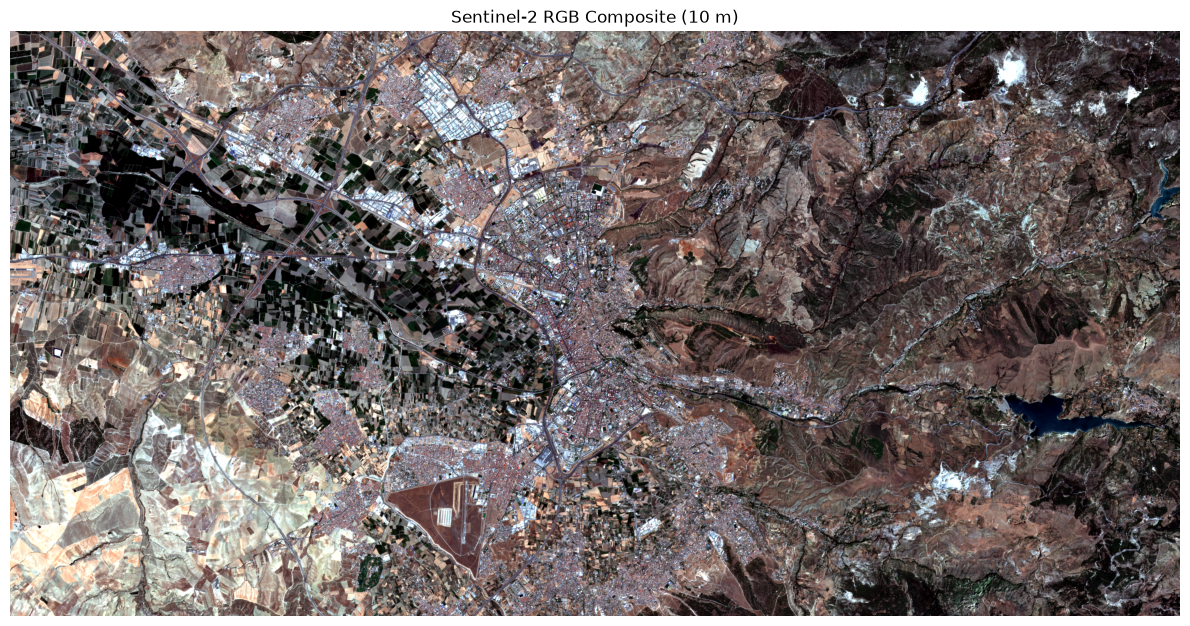

In [2]:
with rio.open(s2_path) as src:
    rgb = src.read([1, 2, 3]).astype(np.float32)

for i in range(3):
    band = rgb[i]
    p2, p98 = np.percentile(band, (2, 98))
    rgb[i] = (band - p2) / (p98 - p2)
rgb = np.clip(rgb, 0, 1)

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(rgb.transpose(1, 2, 0))
ax.set_title("Sentinel-2 RGB Composite (10 m)")
ax.set_axis_off()
plt.tight_layout()
plt.show()

The percentile stretch maps the 2nd and 98th percentile values to 0 and 1, a standard contrast-enhancement step that improves visual interpretability without letting a handful of extreme pixel values wash out the rest of the image.

### C. Run single-patch super-resolution

In [3]:
sr_output = str(OUT_DIR / "sr_output.tif")
sr_image, _ = geoai.super_resolution(
    input_lr_path=s2_path,
    output_sr_path=sr_output,
    rgb_nir_bands=[1, 2, 3, 4],
    window=(700, 1300, 128, 128),
    sampling_steps=100,
)

print(f"Input shape: (4, 128, 128) at 10 m")
print(f"Output shape: {sr_image.shape} at 2.5 m")

LatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 113.63 M params.
Keeping EMAs of 308.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 128, 128) = 65536 dimensions.
making attention of type 'vanilla' with 512 in_channels
Normalization disabled.
Loaded pretrained weights from:  /Users/wulf/.cache/torch/hub/checkpoints/opensr-ldsrs2_v1_0_0.ckpt
Input shape: (4, 128, 128) at 10 m
Output shape: (4, 512, 512) at 2.5 m


`window=(700, 1300, 128, 128)` specifies `(row_offset, col_offset, height, width)` in pixel coordinates, extracting one 128-by-128 patch, LDSR-S2's native input size, from the larger scene. `sampling_steps=100` sets how many denoising steps the diffusion process runs; more steps generally improve quality up to a point, at a proportional cost in processing time.

### D. Compare input and output

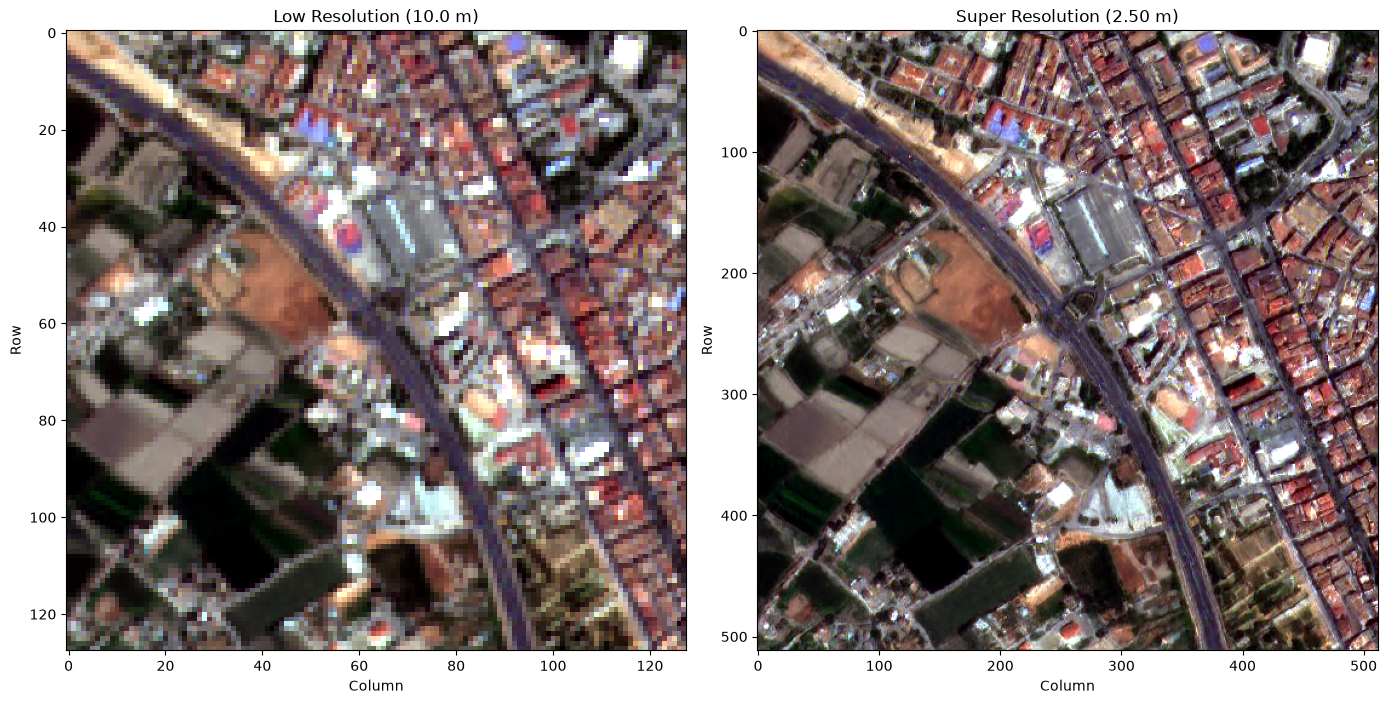

In [4]:
geoai.plot_sr_comparison(s2_path, sr_output, bands=[1, 2, 3])
plt.show()

`plot_sr_comparison()` reads the low-resolution input, windowed to the same region, alongside the saved super-resolution output, letting you assess visually whether the enhancement reveals plausible additional structure, agricultural field boundaries, tree canopies, without needing to build the comparison plot yourself.

### E. Verify the output's georeferencing

In [5]:
with rio.open(sr_output) as src:
    print(f"SR Bands: {src.count}")
    print(f"SR Size: {src.width} x {src.height}")
    print(f"SR CRS: {src.crs}")
    print(f"SR Resolution: {src.res[0]:.2f} m")

SR Bands: 4
SR Size: 512 x 512
SR CRS: EPSG:32630
SR Resolution: 2.50 m


Confirming the output {term}`CRS <Coordinate Reference System>` matches the input, and that the resolution is genuinely 2.5 meters, matters because it is what makes the enhanced output directly usable in GIS software, aligned with your other project data, rather than a plausible-looking image with no reliable spatial reference.

---

## 4. Python reactivation

`with rio.open(s2_path) as src:` is a context manager, the same pattern used for opening rasters throughout this course; it automatically closes the file when the block ends. `src.read([1, 2, 3])` reads specific bands by their 1-based index into a NumPy array, and `.transpose(1, 2, 0)` reorders a channel-first array (bands, height, width) into the channel-last order (height, width, bands) that `matplotlib`'s `imshow()` expects.

---

## 5. Common pitfalls

- **Misreading the `window` parameter order.** It is `(row_offset, col_offset, height, width)`, not `(x, y, width, height)`; double-check this if your patch appears in an unexpected location.
- **Treating raw `uint16` reflectance values as an ordinary 0–255 image.** Sentinel-2 L2A reflectance values range from 0 to 10,000; visualization functions handle this internally, but writing your own plotting code without accounting for it will produce a blank or oversaturated image.
- **Skipping the georeferencing check in step E.** A visually convincing output with broken or missing georeferencing is not usable in a GIS workflow, however good it looks.
- **Assuming higher `sampling_steps` is always worth the cost.** Quality improvements diminish beyond a certain point; there is a practical trade-off between quality and processing time worth testing for your own hardware.

---

## 6. Mini task

Without changing any code, predict what would happen to the output shape if you changed `window=(700, 1300, 128, 128)` to `window=(700, 1300, 64, 64)`. Would this be a valid input for LDSR-S2 as described on the previous page?

:::{dropdown} Sample solution
:class: note

A 64-by-64 window would not match LDSR-S2's native 128-by-128 input size described on the previous page, so this would likely raise an error or require the function to handle a mismatched patch size in some other way, rather than simply producing a smaller, proportionally-scaled output. LDSR-S2 is built around a fixed 128x128 to 512x512 mapping; changing the input patch size is not simply a matter of requesting a different window size without also considering whether the model supports it.
:::

---

## 7. Key takeaways

- `geoai.super_resolution()` runs the full encode-denoise-decode pipeline from the previous page on a specified window of a Sentinel-2 scene.
- The `window` parameter uses `(row_offset, col_offset, height, width)` pixel coordinates, distinct from the `(x, y, width, height)` convention used elsewhere.
- `sampling_steps` trades processing time for output quality, with diminishing returns beyond a certain point.
- Always verify the output's CRS, size, and resolution before treating it as usable; a convincing image is not the same as a correctly georeferenced one.